# 02 · Análisis descriptivo

Evolución nacional y autonómica, distribución territorial, correlaciones y diferencias largas. Las correlaciones de esta sección **no** implican causalidad.

In [1]:
# Configuración: raíz del repositorio en el path
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

# Para comprobar el código sin datos reales: os.environ["INMIG_DEMO"] = "1"
from src import config
print("MODO DEMO (DATOS SINTÉTICOS)" if config.is_demo() else "Datos reales")

Datos reales


In [2]:
from src import data_cleaning as dc
panel = dc.load_panel()
print(panel.shape)
panel.head()

(1300, 31)


,provincia_cod,anio,precio_m2,precio_m2_t4,anio_padron,nacidos_extranjero,extranjeros,poblacion_total,poblacion,ln_precio,...,d_pct_extranjeros,flujo_extranjeros,flujo_nacidos_ext_l1,flujo_nacidos_ext_l2,flujo_extranjeros_l1,flujo_extranjeros_l2,pct_nacidos_ext_l1,pct_nacidos_ext_l2,ccaa,provincia
0,01,1997,1013.650,1039.5,1998,4603,2460,284595,284595,6.921313,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,País Vasco,Araba/Álava
1,01,1998,1151.875,1272.4,1999,4947,2801,285748,285748,7.049146,...,0.115848,0.119819,NaN,NaN,NaN,NaN,1.617386,NaN,País Vasco,Araba/Álava
2,01,1999,1392.325,1467.6,2000,6108,3818,286497,286497,7.238730,...,0.352415,0.355908,0.120874,NaN,0.119819,NaN,1.731246,1.617386,País Vasco,Araba/Álava
3,01,2000,1475.250,1554.6,2001,7850,5462,288793,288793,7.296583,...,0.558671,0.573828,0.406302,0.120874,0.355908,0.119819,2.131959,1.731246,País Vasco,Araba/Álava
4,01,2001,1653.375,1712.2,2002,10573,8031,291860,291860,7.410574,...,0.860342,0.889564,0.608034,0.406302,0.573828,0.355908,2.718210,2.131959,País Vasco,Araba/Álava


In [3]:
from src import analysis
desc = analysis.stage_descriptive(panel)
desc['summary']

,descripcion,count,mean,std,min,25%,50%,75%,max,missing
precio_m2,Precio vivienda (€/m²),1276.0,1233.065,508.048,392.600,863.038,1147.962,1488.869,3045.600,24
dln_precio,Δ ln precio (×100),1216.0,3.107,7.453,-18.661,-1.793,1.972,8.629,25.420,84
pct_nacidos_ext,% nacidos en el extranjero,1300.0,9.542,6.132,0.456,4.624,8.152,13.451,26.069,0
pct_extranjeros,% extranjeros,1300.0,7.508,5.542,0.217,3.196,6.032,11.558,24.312,0
flujo_nacidos_ext,Flujo nacidos ext. (% pob. t-1),1248.0,0.509,0.806,-4.020,0.061,0.327,0.816,5.632,52
flujo_extranjeros,Flujo extranjeros (% pob. t-1),1248.0,0.413,0.856,-4.386,0.003,0.248,0.720,5.895,52


In [4]:
desc['national'].tail(10)

,anio,precio_m2_pond,pct_nacidos_ext,pct_extranjeros,n_provincias
15,2012,1579.045726,14.089893,11.768011,52.0
16,2013,1470.025238,13.434962,10.740524,52.0
17,2014,1434.832904,13.218260,10.144143,52.0
18,2015,1451.111160,13.153270,9.920270,52.0
19,2016,1484.278961,13.270473,9.818762,52.0
20,2017,1526.836104,13.669727,10.133538,52.0
21,2018,1588.591474,14.360286,10.710789,52.0
22,2019,1648.505755,15.239355,11.452185,52.0
23,2020,1631.315310,15.452973,11.480713,52.0
24,2021,1668.979934,15.870345,11.675372,52.0


In [5]:
desc['corr'].round(2)

,precio_m2,dln_precio,pct_nacidos_ext,pct_extranjeros,flujo_nacidos_ext,flujo_extranjeros
precio_m2,1.00,-0.15,0.50,0.47,0.14,0.09
dln_precio,-0.15,1.00,-0.31,-0.29,0.57,0.59
pct_nacidos_ext,0.50,-0.31,1.00,0.96,0.10,0.04
pct_extranjeros,0.47,-0.29,0.96,1.00,0.14,0.09
flujo_nacidos_ext,0.14,0.57,0.10,0.14,1.00,0.99
flujo_extranjeros,0.09,0.59,0.04,0.09,0.99,1.00


## Provincias con mayor variación del peso de la población nacida en el extranjero

In [6]:
desc['long_diff'].sort_values('var_pct_nacidos_ext_pp', ascending=False).head(10)

,provincia_cod,provincia,ccaa,var_precio_pct,var_pct_nacidos_ext_pp,flujo_acum_pct_pob_ini
16,17,Girona,Cataluña,154.151784,19.389768,30.502715
24,25,Lleida,Cataluña,98.009756,18.949710,23.848361
3,04,Almería,Andalucía,131.511205,18.870310,29.515400
7,08,Barcelona,Cataluña,160.215344,17.891058,22.664607
6,07,Illes Balears,Illes Balears,283.144013,17.888632,29.657758
2,03,Alicante/Alacant,Comunitat Valenciana,160.483280,17.022040,25.977639
27,28,Madrid,Comunidad de Madrid,154.034172,16.983054,23.814123
42,43,Tarragona,Cataluña,158.414670,16.910551,25.408405
37,38,Santa Cruz de Tenerife,Canarias,124.591241,16.442333,24.206437
18,19,Guadalajara,Castilla-La Mancha,73.920593,15.903016,28.106897


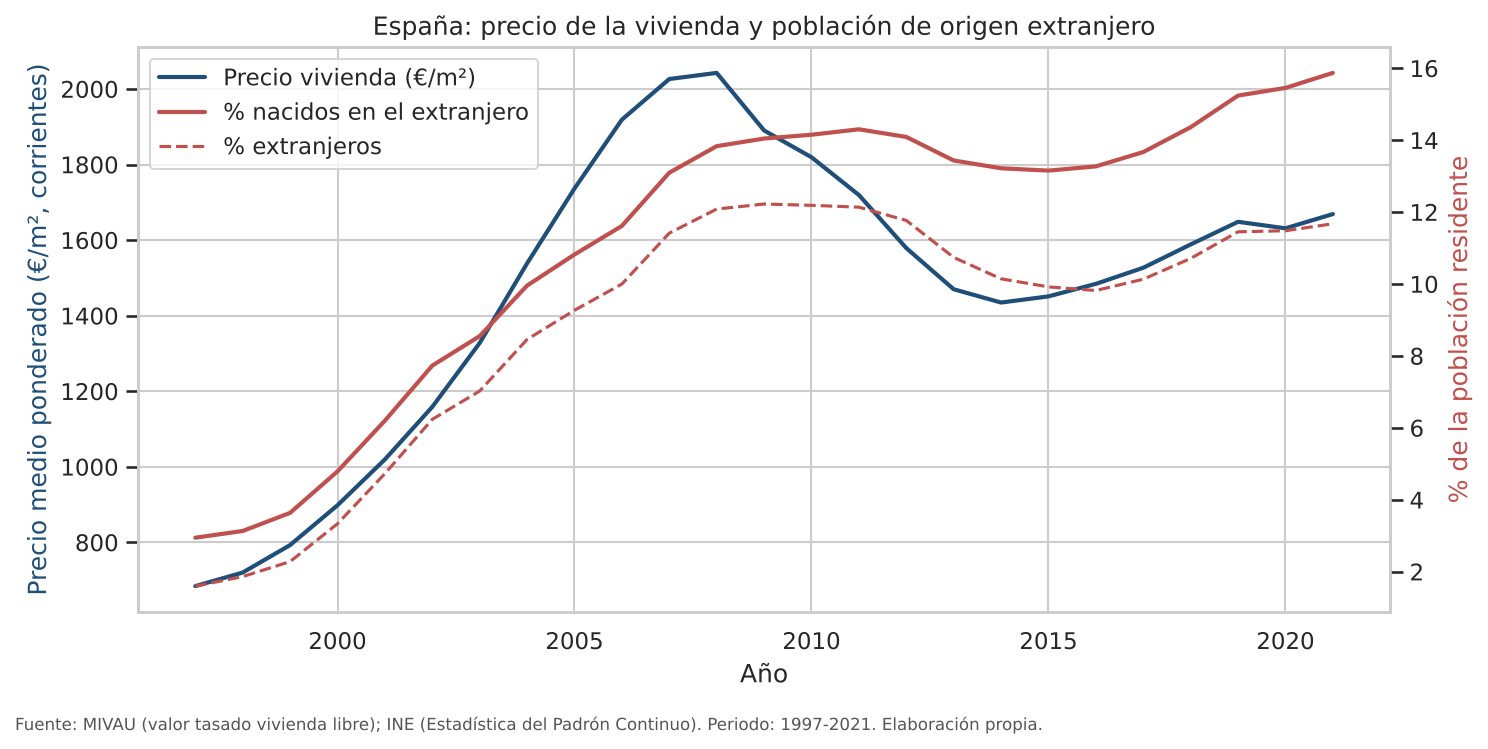

In [7]:
from IPython.display import Image
out = config.out_dirs()
Image(filename=str(out['figures'] / '01_evolucion_nacional.png'))